In [1]:
print("Hello NLP!")

Hello NLP!


                  
                   
                    1:تصنيف الأسئلة الطبية باستخدام معالجة اللغات الطبيعية   
                    تركز المرحلة الأولى على استكشاف البيانات وفهم خصائصها، والتحقق من جودتها، واكتشاف المشكلات المحتملة فيها، ودراسة أساليب المعالجة المسبقة المناسبة للنصوص العربية، تمهيداً لبناء نموذج تصنيف أولي (Baseline Model).   

استيراد المكتبات (Libraries Import)2.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

3. تحميل البيانات (Data Loading)

في هذه المرحلة سنقوم بتحميل ملفات البيانات الخمسة باستخدام مكتبة Pandas، حيث تحتوي هذه الملفات على بيانات التدريب والتحقق والاختبار، بالإضافة إلى قالب تسليم التوقعات وملف ترميز التصنيفات.

In [2]:
train_df = pd.read_csv("train.csv")
validation_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")
sample_submission_df = pd.read_csv("sample_submission.csv")
label_mapping_df = pd.read_excel("labels_mapping.xlsx")

                                              : 3.1  التحقق من تحميل الملفات

بعد قراءة الملفات، سنتحقق من نجاح عملية التحميل من خلال عرض عدد الصفوف والأعمدة الموجودة في كل ملف.

In [3]:
print("حجم بيانات التدريب:", train_df.shape)
print("حجم بيانات التحقق:", validation_df.shape)
print("حجم بيانات الاختبار:", test_df.shape)
print("حجم قالب التسليم:", sample_submission_df.shape)
print("حجم ملف ترميز التصنيفات:", label_mapping_df.shape)

حجم بيانات التدريب: (65845, 3)
حجم بيانات التحقق: (8231, 3)
حجم بيانات الاختبار: (8231, 2)
حجم قالب التسليم: (8231, 2)
حجم ملف ترميز التصنيفات: (11, 2)


4. نظرة عامة على البيانات (Dataset Overview)

في هذا القسم سنستعرض عينات من البيانات للتعرف على شكل الأسئلة الطبية والتصنيفات الموجودة فيها، وفهم بنية الملفات قبل البدء بعملية التحليل.

In [4]:
train_df.head()
validation_df.head()
test_df.head()
label_mapping_df.head()

,Category,Label ID
0,أمراض العيون,0
1,الأمراض الجلدية,1
2,الطب العام,2
3,أمراض نسائية,3
4,الصحة الجنسية,4


4.1 فحص أسماء الأعمدة

سنستعرض أسماء الأعمدة الموجودة في كل ملف للتأكد من بنية البيانات والتعرف على المعلومات المتاحة ضمن كل مجموعة.

In [5]:
print("أعمدة التدريب:")
print(train_df.columns.tolist())

print("\nأعمدة التحقق:")
print(validation_df.columns.tolist())

print("\nأعمدة الاختبار:")
print(test_df.columns.tolist())

print("\nأعمدة ترميز التصنيفات:")
print(label_mapping_df.columns.tolist())

أعمدة التدريب:
['id', 'question', 'category']

أعمدة التحقق:
['id', 'question', 'category']

أعمدة الاختبار:
['id', 'question']

أعمدة ترميز التصنيفات:
['Category', 'Label ID']


4.2 معلومات بنية البيانات

سنستخدم الدالة info() للتعرف على أنواع البيانات في كل عمود، وعدد القيم غير الفارغة، وحجم الذاكرة المستخدم.

In [6]:
train_df.info()
validation_df.info()
test_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65845 entries, 0 to 65844
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        65845 non-null  int64 
 1   question  65845 non-null  object
 2   category  65845 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.5+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8231 entries, 0 to 8230
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        8231 non-null   int64 
 1   question  8231 non-null   object
 2   category  8231 non-null   object
dtypes: int64(1), object(2)
memory usage: 193.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8231 entries, 0 to 8230
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        8231 non-null   int64 
 1   question  8231 non-null   object
dtypes: int64(1), object(1)
memory usage: 128.

5. تحليل توزيع التصنيفات (Class Distribution)

5.1 حساب عدد الأسئلة بكل فئة


In [7]:
class_counts = train_df['category'].value_counts()

class_counts

category
امراض العيون            7988
الأمراض الجلدية         7971
الطب العام              7954
أمراض نسائية            7948
الصحة الجنسية           7710
أمراض الغدد الصماء      7462
امراض الاطفال           5136
ارتفاع ضغط الدم         3999
أمراض الأطفال           2850
صحة الاسنان             2343
امراض الدم              1334
امراض الجهاز التنفسي     954
صحة الأسنان              934
أمراض الجهاز التنفسي     663
أمراض الدم               599
Name: count, dtype: int64

5.2 عرض توزيع التصنيفات باستخدام الرسم البياني

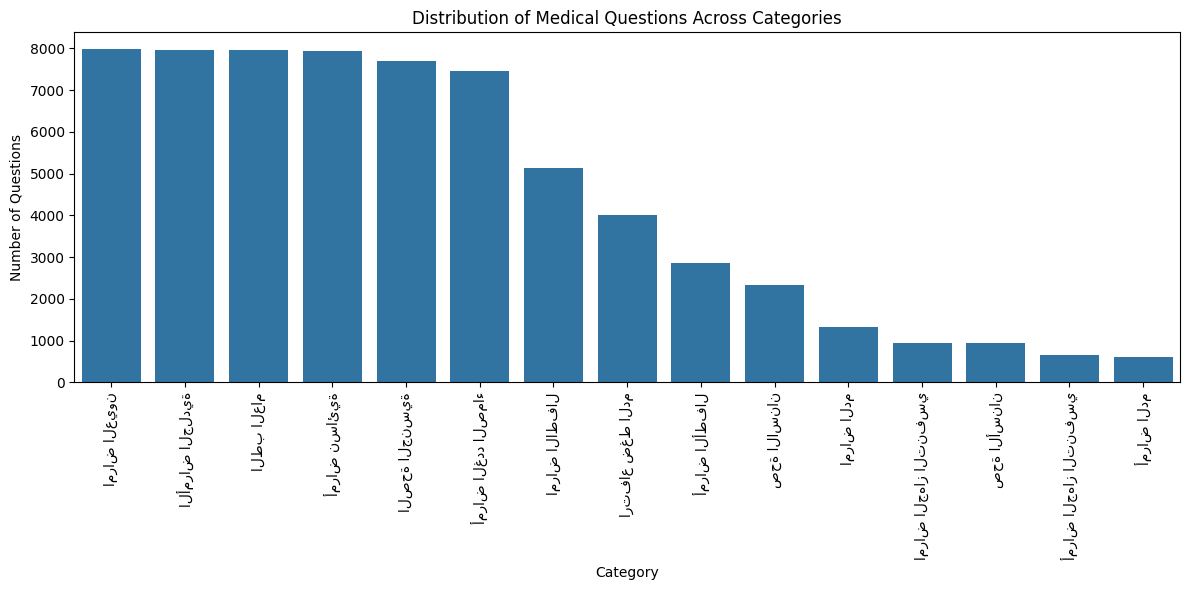

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(x=class_counts.index, y=class_counts.values)

plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Number of Questions")
plt.title("Distribution of Medical Questions Across Categories")

plt.tight_layout()
plt.show()

5.3 تحليل طول الأسئلة الطبية (Question Length Analysis)

رح نقيس طول السؤال بطريقتين:
- Character Length: عدد الأحرف ضمن السؤال.
- Word Length: عدد الكلمات ضمن السؤال



سنحلل طول الأسئلة الطبية من خلال حساب عدد الأحرف وعدد الكلمات في كل سؤال، بهدف استكشاف طبيعة النصوص ومدى اختلاف أطوالها.

In [9]:
train_df['question_char_length'] = train_df['question'].astype(str).str.len()
train_df['question_word_length'] = train_df['question'].astype(str).str.split().str.len()

In [10]:
train_df[['question_char_length', 'question_word_length']].describe()

,question_char_length,question_word_length
count,65845.000000,65845.000000
mean,143.727785,27.461994
std,73.836453,14.082973
min,7.000000,1.000000
25%,88.000000,17.000000
50%,140.000000,27.000000
75%,175.000000,34.000000
max,903.000000,168.000000


### 5.4 التصور البياني لطول الأسئلة (Question Length Visualization)

سنستخدم Histogram لعرض توزيع عدد الكلمات في الأسئلة الطبية، بهدف فهم الأطوال الشائعة ومدى التفاوت بينها.

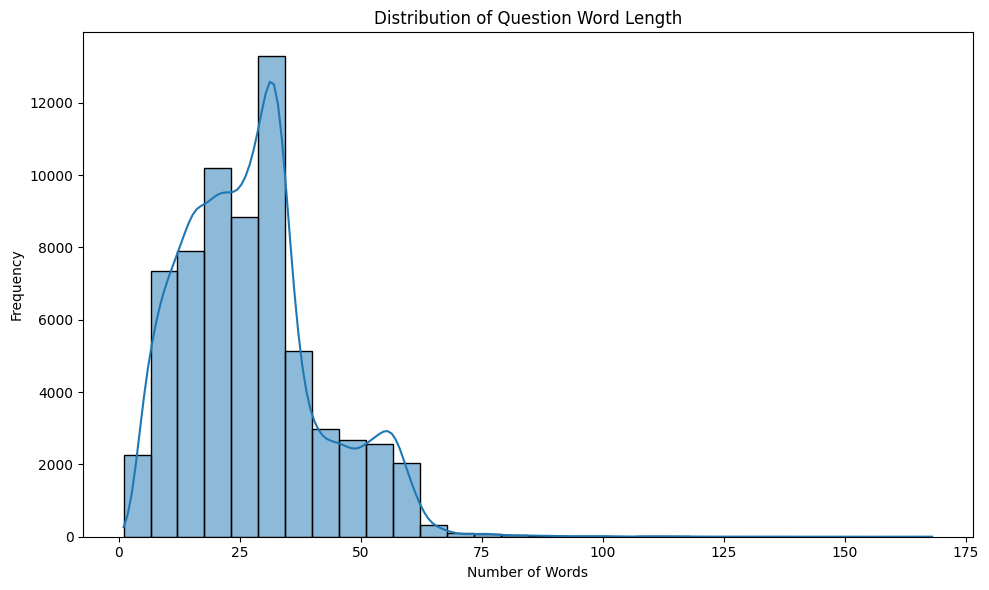

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(data=train_df, x='question_word_length', bins=30, kde=True)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Question Word Length")

plt.tight_layout()
plt.show()

رسم توزيع عدد الأحرف

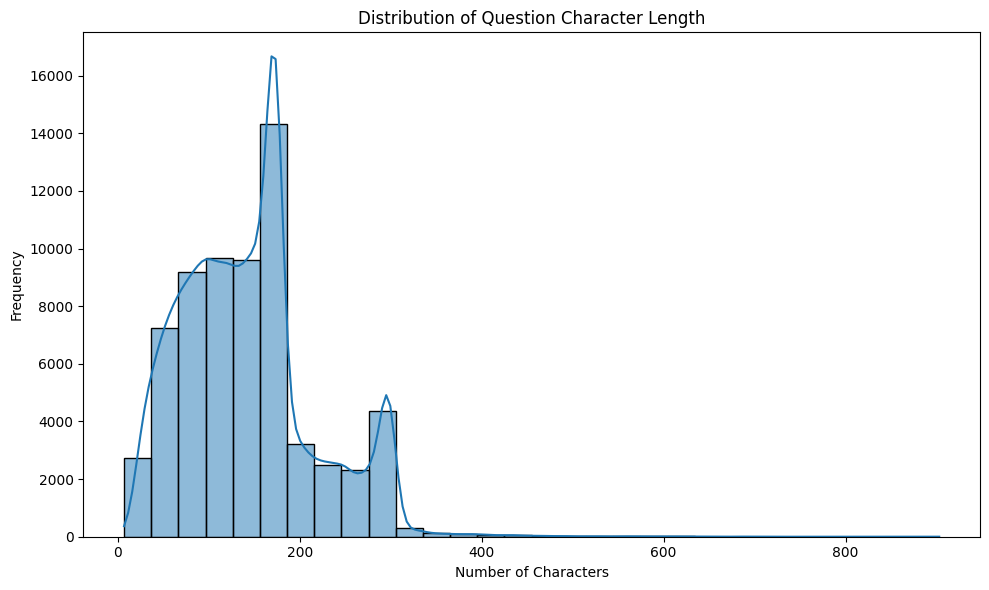

In [12]:
plt.figure(figsize=(10, 6))

sns.histplot(data=train_df, x='question_char_length', bins=30, kde=True)

plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.title("Distribution of Question Character Length")

plt.tight_layout()
plt.show()

6. استكشاف البيانات (Exploratory Data Analysis – EDA)

### 6.1 تحليل الكلمات الأكثر تكرارًا (Word Frequency)

سنستخرج الكلمات من الأسئلة الطبية ونحسب تكرار ظهور كل كلمة، بهدف استكشاف المفردات الأكثر استخدامًا في البيانات.

In [13]:
from collections import Counter
import re

all_text = " ".join(train_df['question'].dropna().astype(str))

words = re.findall(r'\b\w+\b', all_text)

word_counts = Counter(words)

word_counts.most_common(30)

[('من', 41700),
 ('في', 41400),
 ('هل', 28045),
 ('و', 24451),
 ('مع', 12710),
 ('على', 11430),
 ('انا', 10476),
 ('ما', 10406),
 ('لا', 9519),
 ('بعد', 9466),
 ('ان', 8645),
 ('او', 7874),
 ('عندي', 7524),
 ('عليكم', 7387),
 ('السلام', 6901),
 ('هذا', 6810),
 ('عند', 6274),
 ('اعاني', 5747),
 ('ولا', 5480),
 ('وهل', 5355),
 ('الدم', 5352),
 ('يوم', 5144),
 ('لي', 5112),
 ('لدي', 4915),
 ('هو', 4892),
 ('العين', 4781),
 ('منذ', 4752),
 ('قبل', 4502),
 ('طبيعي', 4497),
 ('لكن', 4483)]

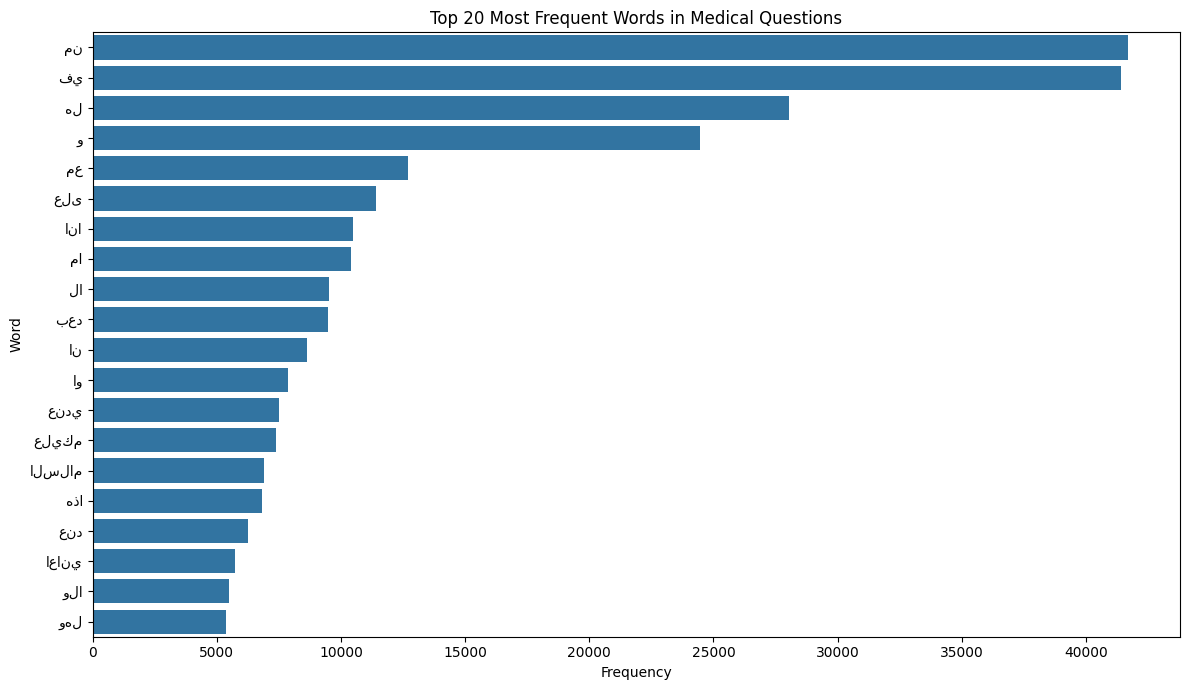

In [14]:
top_words = word_counts.most_common(20)

words_df = pd.DataFrame(top_words, columns=['Word', 'Frequency'])

plt.figure(figsize=(12, 7))

sns.barplot(data=words_df, x='Frequency', y='Word')

plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 20 Most Frequent Words in Medical Questions")

plt.tight_layout()
plt.show()

### 6.2 استكشاف الكلمات الشائعة (Stop Words Exploration)

سنستكشف تكرار الكلمات بعد استبعاد مجموعة أولية من الكلمات الشائعة في اللغة العربية، بهدف التركيز بشكل أكبر على المفردات التي قد تحمل دلالات مرتبطة بمحتوى الأسئلة الطبية.

In [15]:
arabic_stop_words = {
    'في', 'من', 'على', 'الى', 'إلى', 'عن', 'ما', 'ماذا',
    'هل', 'كيف', 'لماذا', 'متى', 'وين', 'مع', 'و', 'او',
    'أو', 'ثم', 'لكن', 'أن', 'إن', 'كان', 'كانت', 'هذا',
    'هذه', 'هو', 'هي', 'انا', 'أنا', 'عندي', 'عند', 'بعد',
    'قبل', 'كل', 'لا', 'لم', 'لن', 'ب', 'ل', 'ك'
}

filtered_words = [
    word for word in words
    if word not in arabic_stop_words
]

filtered_word_counts = Counter(filtered_words)

filtered_word_counts.most_common(30)

[('ان', 8645),
 ('عليكم', 7387),
 ('السلام', 6901),
 ('اعاني', 5747),
 ('ولا', 5480),
 ('وهل', 5355),
 ('الدم', 5352),
 ('يوم', 5144),
 ('لي', 5112),
 ('لدي', 4915),
 ('العين', 4781),
 ('منذ', 4752),
 ('طبيعي', 4497),
 ('دم', 4254),
 ('ام', 4130),
 ('العلم', 4124),
 ('عمري', 4005),
 ('ولكن', 3936),
 ('يوجد', 3901),
 ('سنة', 3851),
 ('علاج', 3788),
 ('جدا', 3649),
 ('الدورة', 3628),
 ('حبوب', 3572),
 ('ممكن', 3372),
 ('اليوم', 3279),
 ('علما', 3277),
 ('اي', 3272),
 ('بس', 3204),
 ('عملت', 3174)]

مجموعة الـ Stop Words الموجودة هون مبدئية وليست قائمة عربية شاملة أو معيارية، وممكن تحتوي على كلمات مهمة طبيًا؛ لذلك هدفنا بهالمرحلة الاستكشاف، وليس اعتمادها نهائيًا بالمعالجة المسبقة.مجموعة الـ Stop Words الموجودة هون مبدئية وليست قائمة عربية شاملة أو معيارية، وممكن تحتوي على كلمات مهمة طبيًا؛ لذلك هدفنا بهالمرحلة الاستكشاف، وليس اعتمادها نهائيًا بالمعالجة المسبقة.

6.3 عرض الكلمات بعد استبعاد الكلمات الشائعة
حتى نقارن الكلمات قبل وبعد استبعاد الـ Stop Words، منعرض الكلمات المتبقية بالرسم البياني.

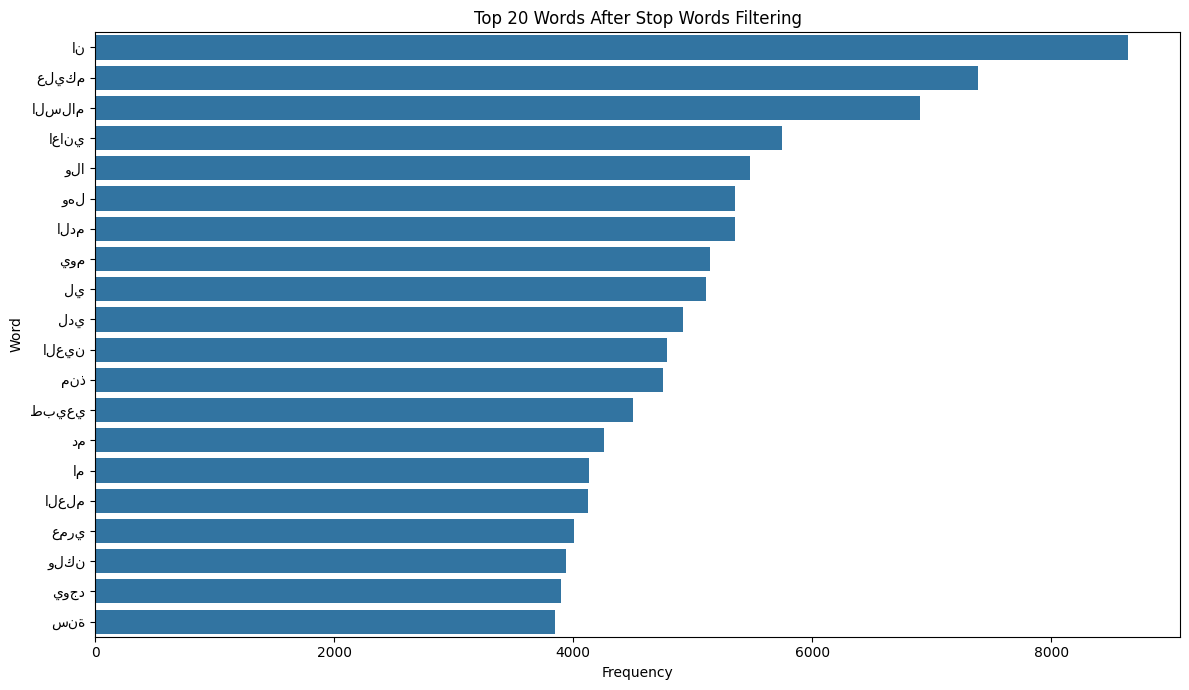

In [16]:
filtered_top_words = filtered_word_counts.most_common(20)

filtered_words_df = pd.DataFrame(
    filtered_top_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 7))

sns.barplot(data=filtered_words_df, x='Frequency', y='Word')

plt.xlabel("Frequency")
plt.ylabel("Word")
plt.title("Top 20 Words After Stop Words Filtering")

plt.tight_layout()
plt.show()

6.4 استكشاف أنماط صياغة الأسئلة (Question Patterns)
كمان فينا نستكشف كيف تبدأ الأسئلة، لأن الأسئلة الطبية ممكن تتكرر فيها صيغ معينة، مثل:
- ما سبب ...
- هل ...
- كيف ...
- متى ...
- أعاني من ...

In [17]:
first_words = (
    train_df['question']
    .dropna()
    .astype(str)
    .str.strip()
    .str.split()
    .str[0]
)

first_word_counts = first_words.value_counts()

first_word_counts.head(20)

question
السلام    6843
هل        5329
انا       4750
اعاني     2325
عندي      1970
أنا       1630
ما        1601
لدي       1594
أعاني     1273
ابني      1125
مرحبا      916
بنتي       851
عملت       844
عمري       832
طفلي       770
سلام       736
كيف        614
دكتور      610
ابنتي      569
كنت        515
Name: count, dtype: int64

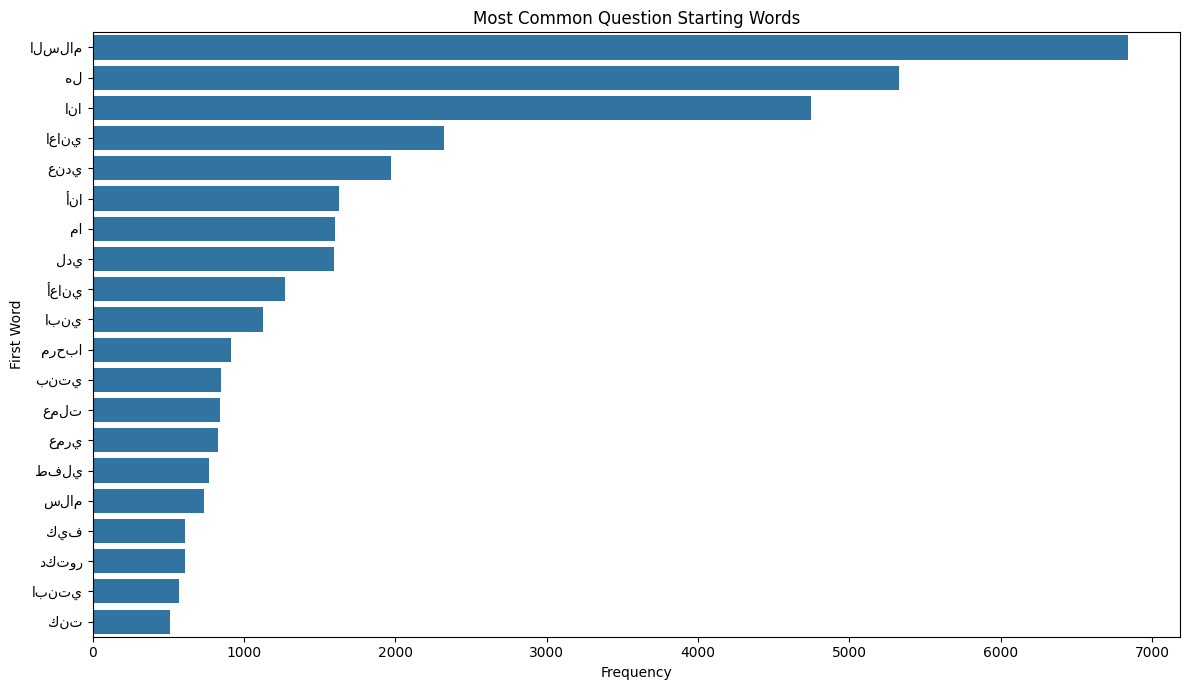

In [18]:
first_words_df = first_word_counts.head(20).reset_index()

first_words_df.columns = ['First Word', 'Frequency']

plt.figure(figsize=(12, 7))

sns.barplot(data=first_words_df, x='Frequency', y='First Word')

plt.xlabel("Frequency")
plt.ylabel("First Word")
plt.title("Most Common Question Starting Words")

plt.tight_layout()
plt.show()

## 7. البحث عن الأسئلة المتكررة أو المتشابهة (Duplicate & Similar Questions)

### 7.1 اكتشاف الأسئلة المتطابقة (Exact Duplicates)

سنفحص الأسئلة المتكررة حرفيًا ضمن بيانات التدريب، مع توحيد المسافات المحيطة بالأسئلة والمسافات المتعددة لأغراض المقارنة فقط، دون تعديل النص الأصلي.

In [19]:
train_df['question_normalized'] = (
    train_df['question']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

duplicate_mask = train_df['question_normalized'].duplicated(keep=False)

exact_duplicates = train_df[duplicate_mask].sort_values('question_normalized')

print("Number of rows involved in exact duplicates:", duplicate_mask.sum())

exact_duplicates[['question', 'category']].head(20)

Number of rows involved in exact duplicates: 109


,question,category
50473,أعالج عند طبيب الأمراض الصدرية عن حساسية القصب...,أمراض الجهاز التنفسي
16076,أعالج عند طبيب الأمراض الصدرية عن حساسية القصب...,أمراض الجهاز التنفسي
9755,أعاني من صداع شديداشبه بالضغط على الرأس من الج...,الطب العام
5127,أعاني من صداع شديداشبه بالضغط على الرأس من الج...,الطب العام
26871,أعاني من مرض التهاب الجلد الدهني المزمن ما هي ...,الأمراض الجلدية
56094,أعاني من مرض التهاب الجلد الدهني المزمن ما هي ...,الأمراض الجلدية
33803,ألبس العدسات اللاصقة كنت أحيانا لا أنزعها ليوم...,امراض العيون
8411,ألبس العدسات اللاصقة كنت أحيانا لا أنزعها ليوم...,امراض العيون
42303,ابني عمرو ٤ شهور والو يومين زي اللي فيه بلغم ب...,امراض الاطفال
56657,ابني عمرو ٤ شهور والو يومين زي اللي فيه بلغم ب...,امراض الاطفال


7.2 اكتشاف الأسئلة المتشابهة (Similar Questions)

الأسئلة المتشابهة مو بالضرورة تكون مكتوبة بنفس الكلمات تمامًا، مثل:
- ما سبب الصداع المستمر؟
- لماذا أعاني من صداع دائم؟
الكتابة مختلفة، لكن المعنى قريب.

لحتى نستكشف هالنوع من الأسئلة، رح نستخدم تقنية TF-IDF مع Cosine Similarity، لقياس مدى التشابه النصي بين الأسئلة.

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

similarity_sample = train_df.drop_duplicates(
    subset='question_normalized'
).sample(n=min(5000, len(train_df)), random_state=42)

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2)
)

question_vectors = vectorizer.fit_transform(
    similarity_sample['question_normalized']
)

neighbors_model = NearestNeighbors(
    n_neighbors=2,
    metric='cosine'
)

neighbors_model.fit(question_vectors)

distances, indices = neighbors_model.kneighbors(question_vectors)

In [21]:
similar_pairs = []

sample_questions = similarity_sample['question_normalized'].tolist()

for i in range(len(sample_questions)):
    neighbor_idx = indices[i][1]
    similarity_score = 1 - distances[i][1]

    if similarity_score >= 0.80:
        similar_pairs.append({
            'Question 1': sample_questions[i],
            'Question 2': sample_questions[neighbor_idx],
            'Similarity': similarity_score
        })

similar_pairs_df = pd.DataFrame(similar_pairs)

similar_pairs_df.sort_values(
    by='Similarity',
    ascending=False
).head(20)

,Question 1,Question 2,Similarity
0,هل من الممكن أن يبدأ الصلع الوراثي من عمر ١٦ م...,هل من الممكن أن يبدأ الصلع الوراثي من عمر ١٦ م...,0.912240
2,هل من الممكن أن يبدأ الصلع الوراثي من عمر ١٦ م...,هل من الممكن أن يبدأ الصلع الوراثي من عمر ١٦ م...,0.912240
1,هل الغشاء في الصورة سليم؟,هل الغشاء في الصورة سليم ام لا,0.863489
3,هل الغشاء في الصورة سليم ام لا,هل الغشاء في الصورة سليم؟,0.863489
4,هل الغشا في الصورة سليم ام لا,هل الغشاء في الصورة سليم ام لا,0.841161


8. فحص جودة البيانات (Data Quality)

تهدف هذه المرحلة إلى التحقق من سلامة البيانات المستخدمة في عملية التدريب، واكتشاف القيم المفقودة، والتناقضات في التصنيفات، والمشكلات النصية، والتكرارات التي قد تؤثر على أداء نموذج التصنيف.

In [22]:
print("Train Missing Values:")
print(train_df.isnull().sum())

print("\nValidation Missing Values:")
print(validation_df.isnull().sum())

print("\nTest Missing Values:")
print(test_df.isnull().sum())

Train Missing Values:
id                      0
question                0
category                0
question_char_length    0
question_word_length    0
question_normalized     0
dtype: int64

Validation Missing Values:
id          0
question    0
category    0
dtype: int64

Test Missing Values:
id          0
question    0
dtype: int64


In [23]:
print("Empty questions in Train:",
      train_df['question'].astype(str).str.strip().eq('').sum())

print("Empty questions in Validation:",
      validation_df['question'].astype(str).str.strip().eq('').sum())

print("Empty questions in Test:",
      test_df['question'].astype(str).str.strip().eq('').sum())

Empty questions in Train: 0
Empty questions in Validation: 0
Empty questions in Test: 0


استنتاج : لايوجد اي قيم فارغة,النتائج عندي بتأكد إنه ما في أسئلة فارغة أو أسئلة مكوّنة من مسافات فقط ضمن أي من مجموعات البيانات الثلاث.

8.1 اكتشاف الاختلافات في كتابة أسماء التصنيفات (Label Inconsistency)
هلق رح نفحص مشكلة سبق وظهرت معنا خلال تحليل توزيع الفئات.

In [24]:
train_df['category'].value_counts()

category
امراض العيون            7988
الأمراض الجلدية         7971
الطب العام              7954
أمراض نسائية            7948
الصحة الجنسية           7710
أمراض الغدد الصماء      7462
امراض الاطفال           5136
ارتفاع ضغط الدم         3999
أمراض الأطفال           2850
صحة الاسنان             2343
امراض الدم              1334
امراض الجهاز التنفسي     954
صحة الأسنان              934
أمراض الجهاز التنفسي     663
أمراض الدم               599
Name: count, dtype: int64

In [25]:
categories = train_df['category'].unique()

for category in categories:
    print(category)

امراض العيون
أمراض الدم
الأمراض الجلدية
الطب العام
الصحة الجنسية
امراض الاطفال
ارتفاع ضغط الدم
أمراض الأطفال
صحة الأسنان
أمراض نسائية
أمراض الغدد الصماء
صحة الاسنان
أمراض الجهاز التنفسي
امراض الدم
امراض الجهاز التنفسي


In [26]:
print("Number of unique categories:",
      train_df['category'].nunique())

Number of unique categories: 15


In [27]:
print("Validation Categories:")
print(sorted(validation_df['category'].unique()))

Validation Categories:
['أمراض الأطفال', 'أمراض الجهاز التنفسي', 'أمراض الدم', 'أمراض الغدد الصماء', 'أمراض نسائية', 'ارتفاع ضغط الدم', 'الأمراض الجلدية', 'الصحة الجنسية', 'الطب العام', 'امراض الاطفال', 'امراض الجهاز التنفسي', 'امراض الدم', 'امراض العيون', 'صحة الأسنان', 'صحة الاسنان']


In [28]:
print("Mapping file columns:")
print(label_mapping_df.columns.tolist())

print("\nMapping file information:")
label_mapping_df.info()

print("\nMapping file content:")
display(label_mapping_df.head(20))

Mapping file columns:
['Category', 'Label ID']

Mapping file information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  11 non-null     object
 1   Label ID  11 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 308.0+ bytes

Mapping file content:


,Category,Label ID
0,أمراض العيون,0
1,الأمراض الجلدية,1
2,الطب العام,2
3,أمراض نسائية,3
4,الصحة الجنسية,4
5,أمراض الغدد الصماء,5
6,أمراض الأطفال,6
7,ارتفاع ضغط الدم,7
8,صحة الأسنان,8
9,أمراض الدم,9


In [29]:
official_categories = set(label_mapping_df['Category'])

train_categories = set(train_df['category'])
validation_categories = set(validation_df['category'])

print("Categories in Train but not in Mapping:")
print(sorted(train_categories - official_categories))

print("\nCategories in Validation but not in Mapping:")
print(sorted(validation_categories - official_categories))

Categories in Train but not in Mapping:
['امراض الاطفال', 'امراض الجهاز التنفسي', 'امراض الدم', 'امراض العيون', 'صحة الاسنان']

Categories in Validation but not in Mapping:
['امراض الاطفال', 'امراض الجهاز التنفسي', 'امراض الدم', 'امراض العيون', 'صحة الاسنان']


In [30]:
category_mapping = {
    'امراض الاطفال': 'أمراض الأطفال',
    'امراض الجهاز التنفسي': 'أمراض الجهاز التنفسي',
    'امراض الدم': 'أمراض الدم',
    'امراض العيون': 'أمراض العيون',
    'صحة الاسنان': 'صحة الأسنان'
}

In [31]:
train_df['category'] = train_df['category'].replace(category_mapping)

validation_df['category'] = validation_df['category'].replace(category_mapping)

In [32]:
print("Train Categories:")
print(sorted(train_df['category'].unique()))

print("\nNumber of Train Categories:")
print(train_df['category'].nunique())

print("\nValidation Categories:")
print(sorted(validation_df['category'].unique()))

print("\nNumber of Validation Categories:")
print(validation_df['category'].nunique())

Train Categories:
['أمراض الأطفال', 'أمراض الجهاز التنفسي', 'أمراض الدم', 'أمراض العيون', 'أمراض الغدد الصماء', 'أمراض نسائية', 'ارتفاع ضغط الدم', 'الأمراض الجلدية', 'الصحة الجنسية', 'الطب العام', 'صحة الأسنان']

Number of Train Categories:
11

Validation Categories:
['أمراض الأطفال', 'أمراض الجهاز التنفسي', 'أمراض الدم', 'أمراض العيون', 'أمراض الغدد الصماء', 'أمراض نسائية', 'ارتفاع ضغط الدم', 'الأمراض الجلدية', 'الصحة الجنسية', 'الطب العام', 'صحة الأسنان']

Number of Validation Categories:
11


8.2 فحص المشكلات النصية (Text Quality)

In [33]:
# Check leading and trailing spaces
leading_trailing_spaces = (
    train_df['question'].astype(str) !=
    train_df['question'].astype(str).str.strip()
)

# Check multiple consecutive spaces
multiple_spaces = (
    train_df['question'].astype(str)
    .str.contains(r'\s{2,}', regex=True)
)

print("Questions with leading/trailing spaces:",
      leading_trailing_spaces.sum())

print("Questions with multiple consecutive spaces:",
      multiple_spaces.sum())

Questions with leading/trailing spaces: 0
Questions with multiple consecutive spaces: 17783


استنتاج:في 17,783 سؤالاً تحتوي على مسافتين أو أكثر متتاليتين
يعني المشكلة موجودة داخل النص نفسه، بين الكلمات أو ضمن تنسيق السؤال


In [34]:
multiple_spaces_examples = train_df.loc[
    multiple_spaces, 'question'
].head(10)

for question in multiple_spaces_examples:
    print(repr(question))
    print("-" * 80)

'السلام عليكم كيف حالك يا دكتور \nعندي مشكلة لها شهرين وهي دوخة وصداع وزغللة او تغبيش في العين وعدم وضوح في الرؤية في بعض الأوقات وعدم استيعاب الكلام أو النطق ممكن اعرف المشكلة'
--------------------------------------------------------------------------------
'انا عمرى ٣٢ سنة متزوج من ٦ سنوات\r\nاتناول دواء بنتالوك ٤٠ يوميا علي مدار خمس سنوات بالاضافة لكلوفرين د وجاست ريج عند الحاجة حدث لي عدم القدرة على الانتصاب فجأة وعدم وجود رغبة جنسية حتى بعد اخذ لبرشامة سياليس ٢٠ ما النصائح و العمل في ذلك وما المدة المتوقعة للرجوع كالسابق بعد التوقف عن ادوية المعدة ؟'
--------------------------------------------------------------------------------
'انا بنت عندي 26 سنه عندي ضغط مرتفع و عندي كرووستيرول عالي شوية و نقرص عالي بسيط و وزني 110 و  طولي 160 باخد اكتنشن 150 بلس و ضغطي بقاله فتره مش بينزل عن 150 علي 100 رغم العلاج'
--------------------------------------------------------------------------------
'انا شاب عمري 26 سنة \r\nبدأت العلاج قبل شهر تقريبا وكتبلي الدكتور على :\r\nابرة نبيدو كل 10 اسابي

استنتاج:هل هذا يعني أن النص خاطئ؟ لا، مو بالضرورة ممكن يكون المستخدم كتب السؤال على عدة أسطر، وهذا تنسيق طبيعي


In [35]:
print("Questions containing \\n:",
      train_df['question'].str.contains('\n', regex=False).sum())

print("Questions containing \\r:",
      train_df['question'].str.contains('\r', regex=False).sum())

Questions containing \n: 10436
Questions containing \r: 7692


In [36]:
contains_both = (
    train_df['question'].str.contains('\n', regex=False) &
    train_df['question'].str.contains('\r', regex=False)
)

print("Questions containing both \\n and \\r:", contains_both.sum())

Questions containing both \n and \r: 7692


استنتاج:رح نحوّل الانتقال بين الأسطر إلى مسافة عادية، حتى يصير السؤال نصاً متصلاً بمرحلة معالجة النصوص

In [37]:
arabic_letter_variants = ['أ', 'إ', 'آ', 'ا']

for letter in arabic_letter_variants:
    count = train_df['question'].str.count(letter).sum()
    print(f"{letter}: {count}")

أ: 77683
إ: 10910
آ: 4254
ا: 1081978


In [38]:
arabic_letter_variants = ['ي', 'ى']

for letter in arabic_letter_variants:
    count = train_df['question'].str.count(letter).sum()
    print(f"{letter}: {count}")

ي: 574529
ى: 45957


In [39]:
arabic_letter_variants = ['ة', 'ه']

for letter in arabic_letter_variants:
    count = train_df['question'].str.count(letter).sum()
    print(f"{letter}: {count}")

ة: 149020
ه: 269119


استنتاج:اختلاف أشكال الحروف


In [43]:
repeated_chars = train_df['question'].str.contains(
    r'(.)\1{2,}',
    regex=True,
    na=False
)
print("Questions with repeated characters:",
      repeated_chars.sum())

C:\Users\Asus\AppData\Local\Temp\ipykernel_8292\3606178546.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  repeated_chars = train_df['question'].str.contains(


Questions with repeated characters: 3617


In [42]:
repeated_examples = train_df.loc[
    repeated_chars, 'question'
].head(15)

for question in repeated_examples:
    print(repr(question))
    print("-" * 80)

'السلام عليكم انا عمري 24 ويظهر لدي حبوب كبيرة عن الفخد والمؤخرة وتؤلمني عند الجلوس وتشبه بشكلها شكل فتحة العين في بعض الاحيان وعندما يخف الالم تترك علامات كبيرة ولون غامق...'
--------------------------------------------------------------------------------
'هل للزنجبيل تاثير على اصحاب السكري والضغط.   \r\nماهى الجرعة المسموح\r\nارجو الإجاب في اقرب وقت .وجزاكم الله خيرا'
--------------------------------------------------------------------------------
'السلام عليكم ورحمة الله وبركاته : \r\nاحب اسأل الأطباء جزاهم الله خير ..\r\nمالفرق بين eltrox و euthrox. ؟ \r\nوهل هذان الدواء نفس الخاصيه الدوائيه؟. علما بأني استخدم التستستيرون وماهو الدواء الافضل من هذين ؟\r\nوشكرا ...'
--------------------------------------------------------------------------------
'ابلغ من العمر ١٤ سنه ولم تبدأ لدي مرحله البلوغ او علاماتُهُ.....اي نصائح؟!؟!'
--------------------------------------------------------------------------------
'دكتور مروان أو عبد العزيز الصورتين في حالة الاسترخاء و الحزق ......هل الغشاء في 

In [48]:
repeated_letters = train_df['question'].str.findall(
    r'(?=([a-zA-Z\u0621-\u064A])\1{2,})'
).str.len().gt(0)

print("Questions with repeated letters:", repeated_letters.sum())

Questions with repeated letters: 349


In [49]:
repeated_punctuation = train_df['question'].str.findall(
    r'([!?.,،؛؟])\1{1,}',
).str.len().gt(0)

print("Questions with repeated punctuation:",
      repeated_punctuation.sum())

Questions with repeated punctuation: 6036


In [47]:
special_chars = train_df['question'].str.findall(
    r'[^\w\s]'
)

special_char_counts = Counter(
    char
    for chars in special_chars
    for char in chars
)

special_char_counts.most_common(30)

[('.', 32199),
 ('؟', 29569),
 ('،', 19736),
 ('ً', 6745),
 ('/', 4478),
 ('(', 3555),
 (')', 3385),
 ('-', 2415),
 ('!', 1772),
 (',', 1719),
 (':', 1550),
 ('=', 603),
 ('+', 568),
 ('%', 495),
 ('?', 448),
 ('ّ', 443),
 ('"', 411),
 ('ُ', 400),
 ('َ', 312),
 ('؛', 210),
 ('ِ', 200),
 ('*', 188),
 ('\u200b', 155),
 ('\u200f', 146),
 ('\\', 133),
 ('٪', 125),
 ('…', 121),
 ('&', 103),
 ('ْ', 100),
 ('⠀', 78)]

In [50]:
invisible_chars = {
    '\u200b': 'Zero Width Space',
    '\u200c': 'Zero Width Non-Joiner',
    '\u200d': 'Zero Width Joiner',
    '\u200e': 'Left-to-Right Mark',
    '\u200f': 'Right-to-Left Mark',
    '\ufeff': 'Byte Order Mark',
    '\u00a0': 'Non-Breaking Space'
}

for char, description in invisible_chars.items():
    count = train_df['question'].str.count(char).sum()
    print(f"{description}: {count}")

Zero Width Space: 155
Zero Width Non-Joiner: 1
Zero Width Joiner: 7
Left-to-Right Mark: 37
Right-to-Left Mark: 146
Byte Order Mark: 0
Non-Breaking Space: 172


المحارف	وظيفتها
Zero Width Space	فاصل مخفي
Zero Width Non-Joiner	منع اتصال الحروف
Zero Width Joiner	المساعدة على اتصال الحروف
Left-to-Right Mark	تحديد اتجاه العرض لليسار إلى اليمين
Right-to-Left Mark	تحديد اتجاه العرض لليمين إلى اليسار
Byte Order Mark	علامة مرتبطة بترميز الملفات
Non-Breaking Space	مسافة تمنع فصل الكلمات بين السطور

مو كل المحارف لازم نحذفها عشوائياً. في مرحلة Text Preprocessing ممكن نتعامل معها بالشكل التالي:
- المحارف المخفية الخاصة بالاتجاه والاتصال: ندرس إزالتها إذا لم تكن ضرورية لمحتوى الأسئلة.
- Zero Width Space: ندرس استبداله بمسافة عادية حتى لا تندمج الكلمات.
- Non-Breaking Space: نستبدله بمسافة عادية.
- BOM: لا نحتاج لمعالجته حالياً لأن العدد صفر.

In [51]:
invisible_chars = {
    '\u200b': 'Zero Width Space',
    '\u200c': 'Zero Width Non-Joiner',
    '\u200d': 'Zero Width Joiner',
    '\u200e': 'Left-to-Right Mark',
    '\u200f': 'Right-to-Left Mark',
    '\ufeff': 'Byte Order Mark',
    '\u00a0': 'Non-Breaking Space'
}

for char, description in invisible_chars.items():

    mask = train_df['question'].str.contains(
        char,
        regex=False,
        na=False
    )

    print(f"\n{description}")
    print("Number of affected questions:", mask.sum())

    for question in train_df.loc[mask, 'question'].head(3):
        print(repr(question))


Zero Width Space
Number of affected questions: 9
'ارهاق وتعب عام وصداع متكرر في كل راسي انفلونزا بتطول وانا ما طبت \u200f\u200b\u200f\u200bمنـِْها والم بكل جسمي بحس'
'لقد أجريت اختبار CBC وحصلت على اختباري وكلها جيدة باستثناء اختبار متوسط \u200b\u200bحجم الصفائح الدموية (MPV) ، وكانت النتيجة 12 فيمتوليتر . هل هناك شيء أخاف منه؟'
'شخص يعاني من حمى مجهولة المصدر ما هي التحاليل التي قد تستطيع اظهار سببها ؟ وهل النفسيه لها دور \u200f\u200bفـي ذلك وماهي اسماء التحاليل التي تساعد على معرفه السبب وشكرا عمر الشخص ٢٠'

Zero Width Non-Joiner
Number of affected questions: 1
'انا كنت مرضعة تأخرت الدورة  رغم انتظامها.. خرج مني قطرات من الدم قبل موعدها بيوم وكان لونه فاتح وانقطع في نفس اليوم قمت بتحليل الحمل بعد تأخرها ب\u200c3أيام وكانت النتيجة سلبية وعندها فطمت من الرضاعة ولكن لم تأتي إلى الآن بعد15 يوم من موعدها\r\nهل يجب ان أقلق من الأمر وازور الطبيب'

Zero Width Joiner
Number of affected questions: 5
'السلام عليكم أختي عمرها 15 سنة طلبت مني فحص غشاء بكرتها لكنني لم أستطيع معرفة هل هو سليم أم ل

فحص الأسئلة التي تحتوي على أرقام 

In [52]:
questions_with_digits = train_df['question'].str.contains(
    r'\d',
    regex=True,
    na=False
)

print(
    "Questions containing digits:",
    questions_with_digits.sum()
)

print(
    "\nPercentage:",
    round(questions_with_digits.mean() * 100, 2),
    "%"
)

train_df.loc[
    questions_with_digits, 'question'
].head(10)

Questions containing digits: 27708

Percentage: 42.08 %


4     انا عمرى ٣٢ سنة متزوج من ٦ سنوات\r\nاتناول دوا...
6     امى تعانى من الضغط المرتفع وهى تبلغ من العمر 4...
8     عندي بنت 7سنوات عندما كانت تطلع اسنان لاول مره...
9     من الادويه التي اثبتت فاعليتها (شخصيا) لمعالجة...
11    انا بنت عندي 26 سنه عندي ضغط مرتفع و عندي كروو...
12    ابني عمره 7 شهور و يومان و لديه امساك يشرب حلي...
14    أنا انسه وعندي 20 سنه من حوالي 6 شهور وانا الد...
16    انا شاب عمري 26 سنة \r\nبدأت العلاج قبل شهر تق...
18    عملت تحليل فيتامين b12 وكانت النتيجة ١٩٨ هل تع...
23    السلام عليكم انا عمري 24 ويظهر لدي حبوب كبيرة ...
Name: question, dtype: object

نفحص أنواع الأرقام

In [53]:
arabic_digits = train_df['question'].str.contains(
    r'[٠-٩]',
    regex=True,
    na=False
)

english_digits = train_df['question'].str.contains(
    r'[0-9]',
    regex=True,
    na=False
)

print("Questions with Arabic-Indic digits:", arabic_digits.sum())

print("Questions with English digits:", english_digits.sum())

print(
    "Questions with both types:",
    (arabic_digits & english_digits).sum()
)

Questions with Arabic-Indic digits: 9915
Questions with English digits: 18851
Questions with both types: 1060


لكن هذا لا يعني حذف الأرقام، بل توحيد طريقة كتابتها فقط
ممكن لاحقاً نحول الأرقام العربية الهندية إلى أرقام لاتينية

In [54]:
url_pattern = r'https?://|www\.'

questions_with_urls = train_df['question'].str.contains(
    url_pattern,
    regex=True,
    case=False,
    na=False
)

print("Questions containing URLs:", questions_with_urls.sum())

train_df.loc[
    questions_with_urls, 'question'
].head(10)

Questions containing URLs: 6


811      السلام عليكم \r\nانا شاب عمري 17 عاما واعاني م...
7943     جماعة انا عايز اشوف اذا كان فتحة الشرج عاندى ط...
8971     عملت تحاليل لدم وظهرت النتيجة كالاتي ارجو الاي...
40098    https://altibbi.com/question/10755السلام عليكم...
40457    هل ممكن لعلاج سوبر قروث ان يزيد طولي بعد عمر 1...
53094    مشكله تضخم الثدى للرجال (gynecomastia)\r\nhttp...
Name: question, dtype: object

In [55]:
email_pattern = r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}'

questions_with_emails = train_df['question'].str.contains(
    email_pattern,
    regex=True,
    na=False
)

print("Questions containing email addresses:", questions_with_emails.sum())

train_df.loc[
    questions_with_emails, 'question'
].head(10)

Questions containing email addresses: 0


Series([], Name: question, dtype: object)

In [56]:
url_questions = train_df.loc[
    questions_with_urls,
    ['id', 'question', 'category']
]

for _, row in url_questions.iterrows():
    print("ID:", row['id'])
    print("Category:", row['category'])
    print("Question:", row['question'])
    print("-" * 100)

ID: 3866
Category: أمراض الدم
Question: السلام عليكم 
انا شاب عمري 17 عاما واعاني من مشكلة خروج الدم من الفرج كما الموضحة بالصورة في الرابط:

http://colorectalsurgeonssydney.com.au/wp-content/uploads/2012/02/pilonidal-sinus.jpg

المشكلة ان الدم يخرج من هذا المنطقة كلما جلست او قمت بكمية صغيرة منذ 3 اسابيع
وحاولت ان اجد حلا عبر وضع القليل من الملح ليتخثر الدم لكن لا فائدة
والان اعاني ببعض الالام كلما اقوم او اجلس على تلك المنطقة
ارجوا منكم مساعدتي 
وشكرا لكم
----------------------------------------------------------------------------------------------------
ID: 25417
Category: ارتفاع ضغط الدم
Question: جماعة انا عايز اشوف اذا كان فتحة الشرج عاندى طبيعية ولا لا وانا جبت صورتها  http://alfaris.net/up/89/alfaris_net_1378738656.jpg
----------------------------------------------------------------------------------------------------
ID: 3423
Category: أمراض الدم
Question: عملت تحاليل لدم وظهرت النتيجة كالاتي ارجو الايضاح في  الصورتين ﺍﻟﺭﻭﺍﺑﻂ
http://im56.gulfup.com/ZioGFz.jpg
http://im56.gulfu

In [57]:
for _, row in url_questions.iterrows():
    print(f"ID: {row['id']}")
    print(f"Category: {row['category']}")
    print(f"Question: {row['question'][:250]}")
    print("=" * 100)

ID: 3866
Category: أمراض الدم
Question: السلام عليكم 
انا شاب عمري 17 عاما واعاني من مشكلة خروج الدم من الفرج كما الموضحة بالصورة في الرابط:

http://colorectalsurgeonssydney.com.au/wp-content/uploads/2012/02/pilonidal-sinus.jpg

المشكلة ان الدم يخرج من هذا المنطقة كلما جلست او قمت بكم
ID: 25417
Category: ارتفاع ضغط الدم
Question: جماعة انا عايز اشوف اذا كان فتحة الشرج عاندى طبيعية ولا لا وانا جبت صورتها  http://alfaris.net/up/89/alfaris_net_1378738656.jpg
ID: 3423
Category: أمراض الدم
Question: عملت تحاليل لدم وظهرت النتيجة كالاتي ارجو الايضاح في  الصورتين ﺍﻟﺭﻭﺍﺑﻂ
http://im56.gulfup.com/ZioGFz.jpg
http://im56.gulfup.com/WO4Nk4.jpg
ID: 81973
Category: صحة الأسنان
Question: https://altibbi.com/question/10755السلام عليكم 
اولا شكر كم على هذا الموقع الطبي الرائع  من فترة ليس قريبة ظهرعلى الضرس خراج وماكنت اشعر بالم منه ... وبديت اشعر بالم تقريبا منذ اسبوع واخذت علاج ابر امبكلوكس تقريبا عشرة ابر بعدين راجعت طبيب وقام بقلع
ID: 12376
Category: أمراض الغدد الصماء
Question: هل ممكن لعلاج سوبر ق

In [58]:
url_questions = train_df.loc[
    questions_with_urls,
    ['id', 'category', 'question']
]

for _, row in url_questions.iterrows():
    print("ID:", row['id'])
    print("Category:", row['category'])
    print("Question:")
    print(row['question'])
    print("=" * 100)

ID: 3866
Category: أمراض الدم
Question:
السلام عليكم 
انا شاب عمري 17 عاما واعاني من مشكلة خروج الدم من الفرج كما الموضحة بالصورة في الرابط:

http://colorectalsurgeonssydney.com.au/wp-content/uploads/2012/02/pilonidal-sinus.jpg

المشكلة ان الدم يخرج من هذا المنطقة كلما جلست او قمت بكمية صغيرة منذ 3 اسابيع
وحاولت ان اجد حلا عبر وضع القليل من الملح ليتخثر الدم لكن لا فائدة
والان اعاني ببعض الالام كلما اقوم او اجلس على تلك المنطقة
ارجوا منكم مساعدتي 
وشكرا لكم
ID: 25417
Category: ارتفاع ضغط الدم
Question:
جماعة انا عايز اشوف اذا كان فتحة الشرج عاندى طبيعية ولا لا وانا جبت صورتها  http://alfaris.net/up/89/alfaris_net_1378738656.jpg
ID: 3423
Category: أمراض الدم
Question:
عملت تحاليل لدم وظهرت النتيجة كالاتي ارجو الايضاح في  الصورتين ﺍﻟﺭﻭﺍﺑﻂ
http://im56.gulfup.com/ZioGFz.jpg
http://im56.gulfup.com/WO4Nk4.jpg
ID: 81973
Category: صحة الأسنان
Question:
https://altibbi.com/question/10755السلام عليكم 
اولا شكر كم على هذا الموقع الطبي الرائع  من فترة ليس قريبة ظهرعلى الضرس خراج وماكنت اشعر بالم م

في نموذجنا الحالي الذي يعتمد على النص فقط (Text Classification):
- لا نحذف السؤال كاملاً.
- نحتفظ بالكلمات المحيطة بالرابط، مثل «تحاليل الدم» و«الصورة».
- يمكن إزالة عنوان الرابط نفسه من النص الذي سندخله إلى النموذج؛ لأنه لا يصف محتوى الصورة.
- نحتفظ بالنص الأصلي دون تعديل، حتى نستطيع المقارنة لاحقاً.
والسبب أن النموذج النصي لا يستطيع فهم صورة التحاليل بمجرد وجود رابطها داخل السؤال.

مثلاً:
النص الأصلي:

عملت تحاليل لدم وظهرت النتيجة أرجو الإيضاح في الصورتين الروابط: http://example.com/image.jpg

النص بعد إزالة الرابط:

عملت تحاليل لدم وظهرت النتيجة أرجو الإيضاح في الصورتين الروابط

In [59]:
print("Number of questions with URLs:", questions_with_urls.sum())

print("\nAffected question IDs:")
print(train_df.loc[questions_with_urls, 'id'].tolist())

Number of questions with URLs: 6

Affected question IDs:
[3866, 25417, 3423, 81973, 12376, 12732]


In [60]:
english_questions = train_df['question'].str.contains(
    r'[a-zA-Z]',
    regex=True,
    na=False
)

print("Questions containing English letters:", english_questions.sum())
print("Percentage:", round(english_questions.mean() * 100, 2), "%")

Questions containing English letters: 6739
Percentage: 10.23 %


In [61]:
english_examples = train_df.loc[
    english_questions,
    ['id', 'category', 'question']
]

for _, row in english_examples.head(20).iterrows():
    print("ID:", row['id'])
    print("Category:", row['category'])
    print("Question:", row['question'])
    print("=" * 100)

ID: 51766
Category: الطب العام
Question: عملت تحليل فيتامين b12 وكانت النتيجة ١٩٨ هل تعتبر طبيعية و هل يحتاج اخذ مكمل له حبوب ام لا
وشكرا
ID: 12086
Category: أمراض الغدد الصماء
Question: اذا نزعت الغدة الدرقية بالكامل ولم تتناول Levothyroxine هل من مخاطر أو أعراض؟
ID: 68951
Category: أمراض العيون
Question: اجريت عمليه الفيمتوليزك منذ شهر و مازلت اري اشعه الوان الطيف حول الضوء في العين اليمني اخبرني الطبيب انها اعراض طبيعيه تقل مع الوقت ولكن حتى الان لم اشعر انها تقل ابدا حتي مع استخدام قطره  (  HYDRATION UD ) فهل يمكن ان تقل فعلا لان الامر مزعج للغايه
ID: 3280
Category: أمراض الدم
Question: Erythropoietin هو مخدر فكيف قريبتي بتاخده على اساس انه علاج للانيميا
ID: 11967
Category: أمراض الغدد الصماء
Question: السلام عليكم ورحمة الله وبركاته : 
احب اسأل الأطباء جزاهم الله خير ..
مالفرق بين eltrox و euthrox. ؟ 
وهل هذان الدواء نفس الخاصيه الدوائيه؟. علما بأني استخدم التستستيرون وماهو الدواء الافضل من هذين ؟
وشكرا ...
ID: 64469
Category: أمراض الأطفال
Question: طفلة تبلغ 5 اشهر تعانى من ارتف

الأحرف الإنجليزية ليست بالضرورة ضوضاء (Noise).

من الأمثلة السابقة نلاحظ أنها تحمل معلومات طبية مهمة، مثل:
- أسماء الأدوية.
- أسماء الفيتامينات.
- نتائج التحاليل.
- المصطلحات الطبية الأجنبية.

In [62]:
import re
from collections import Counter

latin_words = train_df['question'].str.findall(
    r'[a-zA-Z]+'
)

latin_word_counts = Counter(
    word.lower()
    for words in latin_words
    for word in words
)

latin_word_counts.most_common(30)

[('tsh', 1233),
 ('t', 824),
 ('mg', 513),
 ('ml', 485),
 ('l', 312),
 ('b', 270),
 ('fsh', 268),
 ('d', 264),
 ('lh', 220),
 ('ng', 216),
 ('hiv', 200),
 ('ft', 189),
 ('cm', 166),
 ('cbc', 158),
 ('c', 149),
 ('dl', 134),
 ('free', 132),
 ('a', 129),
 ('g', 123),
 ('sph', 104),
 ('s', 101),
 ('h', 99),
 ('anti', 96),
 ('cyl', 96),
 ('mm', 93),
 ('crp', 87),
 ('e', 78),
 ('axis', 77),
 ('o', 74),
 ('mcv', 73)]

حالياً خلينا نعتمد هذه القرارات:
- الاحتفاظ بالمصطلحات الطبية الأجنبية.
- الاحتفاظ بأسماء الأدوية والتحاليل.
- الاحتفاظ بوحدات القياس.
- عدم تحويل جميع الأحرف إلى العربية.
- استخدام lower() لتوحيد حالة الأحرف الإنجليزية لاحقاً.

In [63]:
emoji_pattern = (
    r'[\U0001F300-\U0001FAFF'
    r'\U00002600-\U000027BF]'
)

questions_with_emojis = train_df['question'].str.contains(
    emoji_pattern,
    regex=True,
    na=False
)

print("Questions containing emojis:", questions_with_emojis.sum())
print(
    "Percentage:",
    round(questions_with_emojis.mean() * 100, 2),
    "%"
)

Questions containing emojis: 16
Percentage: 0.02 %


In [64]:
emoji_questions = train_df.loc[
    questions_with_emojis,
    ['id', 'category', 'question']
]

for _, row in emoji_questions.iterrows():
    print("ID:", row['id'])
    print("Category:", row['category'])
    print("Question:", row['question'])
    print("=" * 100)

ID: 24894
Category: ارتفاع ضغط الدم
Question: لما أكل {جبس ليز}الذي يحتوي على(ملح و خل)
أشعر بألم في الاكتاف و أسفل الكتف☜العضلات
و احيانآ الم لثواني في منطقة القلب مع تعب
هل له علاقة بالضغط او مرض؟
انا تركت أكله من قبل سنوات{للحذر من مظاعفات}
☜الآلم يأتي فقط عند أكله☞
ID: 80865
Category: صحة الأسنان
Question: سلآم دكتــــــور آلآسنــــآن , , آنـــآ آحتـــآج وصفـــــآت لتبييــــض آلآسنــــآن , مع آلعلــم آننـــــــــ☺ــــي آنظفــــهم بآلمعجـــــون كولجـــــــيت , , هل من حـــــل ؟
ID: 77742
Category: أمراض نسائية
Question: وصفت لي الدكتورة دواء fertile first f  للنساء عندما اخدت الدواء ورجعت إلى البيت وجدته fertile first للرجال اخدت منه حبتين بعد ذلك انتبهت لرمز الرجال ♂️ هل هناك ضرر إذا أخذته ؟
ID: 2753
Category: أمراض الدم
Question: هل شرب كوب شاي واحد في اليوم يؤثر على الهيموجلوبين ارجوو الرد على سؤالي وشكرررراً ❤️
ID: 72957
Category: أمراض العيون
Question: يوجد في عدسة عيني اليسرى شيء مثل الحبة و بالتحديد في محيط قزحية العين ظهرت منذ يومين فما سبب هذه الحبة؟ و ارجو منكم رد سريع و ش

نعتمد قرار إزالة الرموز التعبيرية (Emojis) من النص أثناء Text Preprocessing.
حتى الرمز ♂️ في السؤال رقم 77742، رغم أنه يحمل معنى «ذكر»، فالسياق النصي نفسه يحتوي على عبارة «رمز الرجال»، وبالتالي يمكن للنموذج الاستفادة من الكلمات دون الحاجة إلى الرمز.

In [66]:
repeated_words = train_df['question'].str.findall(
    r'\b(\w+)(?:\s+\1){2,}\b'
).str.len().gt(0)

print("Questions with repeated consecutive words:", repeated_words.sum())

Questions with repeated consecutive words: 10


In [67]:
train_df.loc[
    repeated_words,
    ['id', 'category', 'question']
]

,id,category,question
8466,81983,صحة الأسنان,ارجوك ارجوك ارجوك انا شاب 22 سنة واعاني من تسو...
21482,40896,الصحة الجنسية,عندي مشكله كبيره جدا جدا جدا والله العضو عندي ...
30700,76823,أمراض نسائية,انتهت زوجتي من الدوه 1/26 وعملت فحص منزل وكانت...
30945,48171,الطب العام,اناطالبةطب اسنان ومن فترة شهر تعرضت لوخزة في ف...
32516,66711,أمراض العيون,انا بصراحة عيني يا دكاتره بتعمل صوت تك تك تك و...
40842,54624,الطب العام,كسر المحرر الزيبق في أيدي وانا عندي جرح هل هذا...
48939,63346,أمراض الأطفال,بنتي عندها 3 سنوات وكانت تتكلم بطلاقة وكلامها ...
54057,43575,الصحة الجنسية,ارجوكم ارجوكم ارجوكم اقبلوا السؤال \r\nدكتور أ...
57107,33898,الأمراض الجلدية,شعر يتساقط بغزر واصبح قصير جدا جدا جدا جدا جدا...
62174,61104,أمراض الأطفال,أخبرني الطبيب ان ابني لديه مرض الداء البطني ال...



 لاحقاً في مرحلة Text Preprocessing تقليل التكرار المتتالي للكلمات إلى ظهور واحد
مثلاً:

قبل المعالجة

ارجوك ارجوك ارجوك اقبلوا السؤال

بعد المعالجة

ارجوك اقبلوا السؤال

In [68]:
normalized_questions = (
    train_df['question']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

duplicate_mask = normalized_questions.duplicated(keep=False)

print("Questions involved in duplicates:", duplicate_mask.sum())
print("Number of unique duplicated questions:",
      normalized_questions[duplicate_mask].nunique())

Questions involved in duplicates: 109
Number of unique duplicated questions: 52


In [69]:
duplicate_check = pd.DataFrame({
    'normalized_question': normalized_questions,
    'category': train_df['category']
})

duplicate_summary = (
    duplicate_check[duplicate_mask]
    .groupby('normalized_question')
    .agg(
        count=('category', 'size'),
        number_of_categories=('category', 'nunique'),
        categories=('category', lambda x: list(x.unique()))
    )
)

conflicting_duplicates = duplicate_summary[
    duplicate_summary['number_of_categories'] > 1
]

print("Number of duplicated questions with conflicting categories:",
      len(conflicting_duplicates))

print("\nConflicting duplicates:")
print(conflicting_duplicates)

Number of duplicated questions with conflicting categories: 4

Conflicting duplicates:
                                                    count  \
normalized_question                                         
انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه...      2   
انا عندي ارتفاع في الضغط استخدم دواء amlocard و...      2   
عندي بردودة وتعرق في اليدين ولما عملت تحاليل قل...      2   
نسبة الانسولين صائم 13.2 وتحليل السكر صائم 95 ه...      2   

                                                    number_of_categories  \
normalized_question                                                        
انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه...                     2   
انا عندي ارتفاع في الضغط استخدم دواء amlocard و...                     2   
عندي بردودة وتعرق في اليدين ولما عملت تحاليل قل...                     2   
نسبة الانسولين صائم 13.2 وتحليل السكر صائم 95 ه...                     2   

                                                                               categories

In [71]:
for i, text in enumerate(conflict_texts, start=1):
    rows = train_df.loc[
        normalized_questions == text,
        ['id', 'category', 'question']
    ]

    print(f"\n{'=' * 30} Conflict {i} {'=' * 30}")

    print("IDs and Categories:")
    print(rows[['id', 'category']].to_string(index=False))

    print("\nQuestion:")
    print(rows.iloc[0]['question'])


============================== Conflict 1 ==============================
IDs and Categories:
   id   category
50982 الطب العام
 2362 أمراض الدم

Question:
انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب

============================== Conflict 2 ==============================
IDs and Categories:
   id           category
 5633 أمراض الغدد الصماء
22043    ارتفاع ضغط الدم

Question:
انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180/106 وتكون الاخيرة 150/83 هل هاذا طبيعي ام ماذ

============================== Conflict 3 ==============================
IDs and Categories:
   id           category
 7245 أمراض الغدد الصماء
32344    الأمراض الجلدية

Question:
عندي بردودة وتعرق في اليدين ولما عملت تحاليل قلولي عندك فرط في نشاط الغدة الدرقية

كيف بقدر أقلل من نشاطها الزائد
وإيش الأشياء إلي لو سويتها ممكن تتحكم بكمية إفراز العرق

============================== Conflict 4 =

In [72]:
for i, text in enumerate(conflict_texts, start=1):
    rows = train_df.loc[
        normalized_questions == text,
        ['id', 'category']
    ]

    print(f"\nConflict {i}")
    print(rows.to_string(index=False))


Conflict 1
   id   category
50982 الطب العام
 2362 أمراض الدم

Conflict 2
   id           category
 5633 أمراض الغدد الصماء
22043    ارتفاع ضغط الدم

Conflict 3
   id           category
 7245 أمراض الغدد الصماء
32344    الأمراض الجلدية

Conflict 4
   id           category
 6739 أمراض الغدد الصماء
52958         الطب العام


عدد الأسئلة الفريدة المكررة: 52.



عدد الصفوف المشاركة في التكرار: 109.



عدد الأسئلة المكررة ذات التصنيفات المتعارضة: 4.



عدد النسخ المتعارضة: 8 صفوف.


In [73]:
train_questions = (
    train_df['question']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

validation_questions = (
    validation_df['question']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

common_questions = set(train_questions) & set(validation_questions)

print("Questions shared between Train and Validation:",
      len(common_questions))

Questions shared between Train and Validation: 7


In [74]:
for question in common_questions:
    train_rows = train_df.loc[
        train_questions == question,
        ['id', 'category']
    ]

    validation_rows = validation_df.loc[
        validation_questions == question,
        ['id', 'category']
    ]

    print("\nQuestion:", question)

    print("Train:")
    print(train_rows.to_string(index=False))

    print("Validation:")
    print(validation_rows.to_string(index=False))

    print("-" * 100)


Question: إبني 8 شهور ولم يبدأ التسنين جبتله هاي كال لكن رفضه.وهل صحيح لو مشي مش هيسنن غير متاخر
Train:
   id      category
60126 أمراض الأطفال
Validation:
   id      category
60125 أمراض الأطفال
----------------------------------------------------------------------------------------------------

Question: السلام عليكم ورحمة الله وبركاته ممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمرها ٢١ سنة
Train:
   id   category
51083 الطب العام
Validation:
  id   category
2373 أمراض الدم
----------------------------------------------------------------------------------------------------

Question: هل غشاء البكارة سليم ام لا
Train:
   id      category
36992 الصحة الجنسية
Validation:
   id      category
39629 الصحة الجنسية
----------------------------------------------------------------------------------------------------

Question: تحليل سكر تراكمي قبل ٣ شهور ٦.٣ وكان وزني وقتها ١١٧ واليوم نتيجه التحليل ٥.٣ ونزل من وزني ٢٠ ك هل يعني ذلك تجاوزي مرحله ماقبل السكري واص

In [75]:
cross_duplicates = pd.DataFrame({
    'question': list(common_questions)
})

train_labels = (
    train_df.assign(normalized_question=train_questions)
    .groupby('normalized_question')['category']
    .apply(lambda x: set(x))
)

validation_labels = (
    validation_df.assign(normalized_question=validation_questions)
    .groupby('normalized_question')['category']
    .apply(lambda x: set(x))
)

for question in common_questions:
    t_labels = train_labels.get(question, set())
    v_labels = validation_labels.get(question, set())

    print("Question:", question[:100])
    print("Train categories:", t_labels)
    print("Validation categories:", v_labels)
    print("Same labels:", t_labels == v_labels)
    print("-" * 80)

Question: إبني 8 شهور ولم يبدأ التسنين جبتله هاي كال لكن رفضه.وهل صحيح لو مشي مش هيسنن غير متاخر
Train categories: {'أمراض الأطفال'}
Validation categories: {'أمراض الأطفال'}
Same labels: True
--------------------------------------------------------------------------------
Question: السلام عليكم ورحمة الله وبركاته ممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية
Train categories: {'الطب العام'}
Validation categories: {'أمراض الدم'}
Same labels: False
--------------------------------------------------------------------------------
Question: هل غشاء البكارة سليم ام لا
Train categories: {'الصحة الجنسية'}
Validation categories: {'الصحة الجنسية'}
Same labels: True
--------------------------------------------------------------------------------
Question: تحليل سكر تراكمي قبل ٣ شهور ٦.٣ وكان وزني وقتها ١١٧ واليوم نتيجه التحليل ٥.٣ ونزل من وزني ٢٠ ك هل يع
Train categories: {'أمراض الغدد الصماء'}
Validation categories: {'أمراض الغدد الصماء'}
Same labels: True
----------------

ا نعتبرها بالضرورة خطأً طبياً أو تصنيفاً خاطئاً، بل نسجلها كالتالي:

Ambiguous / Conflicting Label

أي سؤال يحتمل أكثر من تصنيف،
 
لكن البيانات أعطته تصنيفين مختلفين   



7 أسئلة مشتركة بين Train وValidation.

6 أسئلة بتصنيفات متطابقة.

سؤال واحد بتصنيفين مختلفين.

In [76]:
datasets = {
    'Train': train_df,
    'Validation': validation_df,
    'Test': test_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Duplicate IDs:", df['id'].duplicated().sum())


Train
Duplicate IDs: 0

Validation
Duplicate IDs: 0

Test
Duplicate IDs: 0


In [77]:
datasets = {
    'Train': train_df,
    'Validation': validation_df,
    'Test': test_df
}

for name, df in datasets.items():

    normalized = (
        df['question']
        .astype(str)
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

    print(f"\n{name}")
    print("Duplicated rows:", normalized.duplicated().sum())
    print("Unique duplicated questions:",
          normalized[normalized.duplicated(keep=False)].nunique())


Train
Duplicated rows: 57
Unique duplicated questions: 52

Validation
Duplicated rows: 0
Unique duplicated questions: 0

Test
Duplicated rows: 1
Unique duplicated questions: 1


In [78]:
train_questions = (
    train_df['question']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

test_questions = (
    test_df['question']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

common_train_test = set(train_questions) & set(test_questions)

print("Questions shared between Train and Test:",
      len(common_train_test))

Questions shared between Train and Test: 12


In [79]:
for question in common_train_test:

    train_rows = train_df.loc[
        train_questions == question,
        ['id', 'category']
    ]

    test_rows = test_df.loc[
        test_questions == question,
        ['id']
    ]

    print("\nQuestion:", question[:150])

    print("Train:")
    print(train_rows.to_string(index=False))

    print("Test:")
    print(test_rows.to_string(index=False))

    print("-" * 80)


Question: السلام عليكم اريدعلاج للربو مجرب و مضمون علما بأنني اعاني من ضيق في التنفس اثناء الذهاب الي النوم و كذلك في ساعة الصباح المبكر افيدوني مشكورين
Train:
  id             category
1660 أمراض الجهاز التنفسي
Test:
  id
1656
--------------------------------------------------------------------------------

Question: عانى أخي من التهاب رئوي جراء إصابته في كورونا السنة الماضية و هو مصاب بها الآن فكيف نتصرف؟هل يجب إعطائه الكورتيزون أم ماذا فقد بدأت حرارته اليوم ترتفع
Train:
   id   category
52131 الطب العام
Test:
 id
384
--------------------------------------------------------------------------------

Question: كيف حالة الغشاء في الصورة
Train:
   id      category
39302 الصحة الجنسية
38887 الصحة الجنسية
Test:
   id
38941
--------------------------------------------------------------------------------

Question: مرحبا اود الاستفسار عن هذه الفحوصات هل جميعها من تحاليل الدم ام لا ؟ وهل اخذ هذه الادوية تؤثر في نتيجتها ام لا ١-(VIVAXIN 500 _Levofloxacin) 2-قطرة ال
Train:
   id   category
520

In [80]:
official_categories = set(label_mapping_df['Category'])

for name, df in {
    'Train': train_df,
    'Validation': validation_df
}.items():

    dataset_categories = set(df['category'].dropna())

    unknown_categories = dataset_categories - official_categories

    print(f"\n{name}")
    print("Number of categories:", len(dataset_categories))
    print("Unknown categories:", unknown_categories)


Train
Number of categories: 11
Unknown categories: set()

Validation
Number of categories: 11
Unknown categories: set()


:أولاً
 التكرار داخل Train

يوجد 52 سؤالاً مكرراً، وهذا يعني أن بعض الأسئلة لها وزن أكبر في بيانات التدريب لأنها تظهر أكثر من مرة.

وقد يؤدي ذلك إلى زيادة تأثير هذه الأسئلة على تعلم النموذج.

ثانياً: التكرار داخل Validation

لا يوجد أي سؤال مكرر داخل Validation، وهذه نقطة جيدة من ناحية جودة البيانات.

ثالثاً: التكرار داخل Test

يوجد سؤال واحد مكرر داخل Test. هذا يعني أن بعض التوقعات قد تكون متعلقة بالسؤال نفسه، لكن لا نستطيع تقييم صحة التصنيف لأن Test لا يحتوي على Labels.

رابعاً: التداخل بين Train وValidation

وجدنا 7 أسئلة مشتركة، منها 6 بتصنيفات متطابقة وواحد بتصنيفين مختلفين.

وهذا قد يؤدي إلى تقييم متفائل لأداء النموذج؛ لأنه سبق أن شاهد بعض أسئلة Validation أثناء التدريب.

خامساً: التداخل بين Train وTest

وجدنا 12 سؤالاً مشتركاً. وهذا يعني أن بعض أسئلة الاختبار موجودة مسبقاً في بيانات التدريب، وقد يستطيع النموذج الاستفادة من رؤيتها سابقاً بدلاً من تعميم ما تعلمه على أسئلة جديدة.